In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from pathlib import Path
import json

In [4]:
from ucimlrepo import fetch_ucirepo

# 從 UCI 取得 CCPP 資料
ccpp = fetch_ucirepo(id=294)

# X：四個輸入變數
X = ccpp.data.features.copy()

# y：發電輸出
y = ccpp.data.targets.copy()

# Target
在相同 Activation、Loss、Optimizer 等條件下，網路複雜度與訓練樣本數如何影響預測能力？

在相同訓練資料與訓練條件下，增加神經網路的隱藏層節點數及層數，是否能有效改善 CCPP 發電量的預測能力？

# Data Reading

In [5]:
# 合併成完整資料表
df = pd.concat([X, y], axis=1)

print("資料維度：", df.shape)
print("\n欄位名稱：", df.columns.tolist())

display(df.head(10))

資料維度： (9568, 5)

欄位名稱： ['AT', 'V', 'AP', 'RH', 'PE']


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90
5,26.27,59.44,1012.23,58.77,443.67
6,15.89,43.96,1014.02,75.24,467.35
7,9.48,44.71,1019.12,66.43,478.42
8,14.64,45.00,1021.78,41.25,475.98
9,11.74,43.56,1015.14,70.72,477.50


In [17]:
# 1. 資料型別
print("資料型別：")
display(df.dtypes)

# 2. 缺失值
print("\n各欄位缺失值：")
display(df.isnull().sum())

# 3. 完全重複資料
print("\n完全重複列數：", df.duplicated().sum())

# 4. 描述統計
print("\n描述統計：")
display(df.describe().T)

資料型別：


AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object


各欄位缺失值：


AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


完全重複列數： 41

描述統計：


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


In [6]:
# 移除完全重複資料

# 保留原始 df，建立清理後的版本
df_clean = df.drop_duplicates().reset_index(drop=True)

print("原始資料筆數：", len(df))
print("清理後資料筆數：", len(df_clean))
print("移除重複筆數：", len(df) - len(df_clean))

print("\n清理後剩餘重複列數：")
print(df_clean.duplicated().sum())

display(df_clean.head())

原始資料筆數： 9568
清理後資料筆數： 9527
移除重複筆數： 41

清理後剩餘重複列數：
0


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## description -- plot

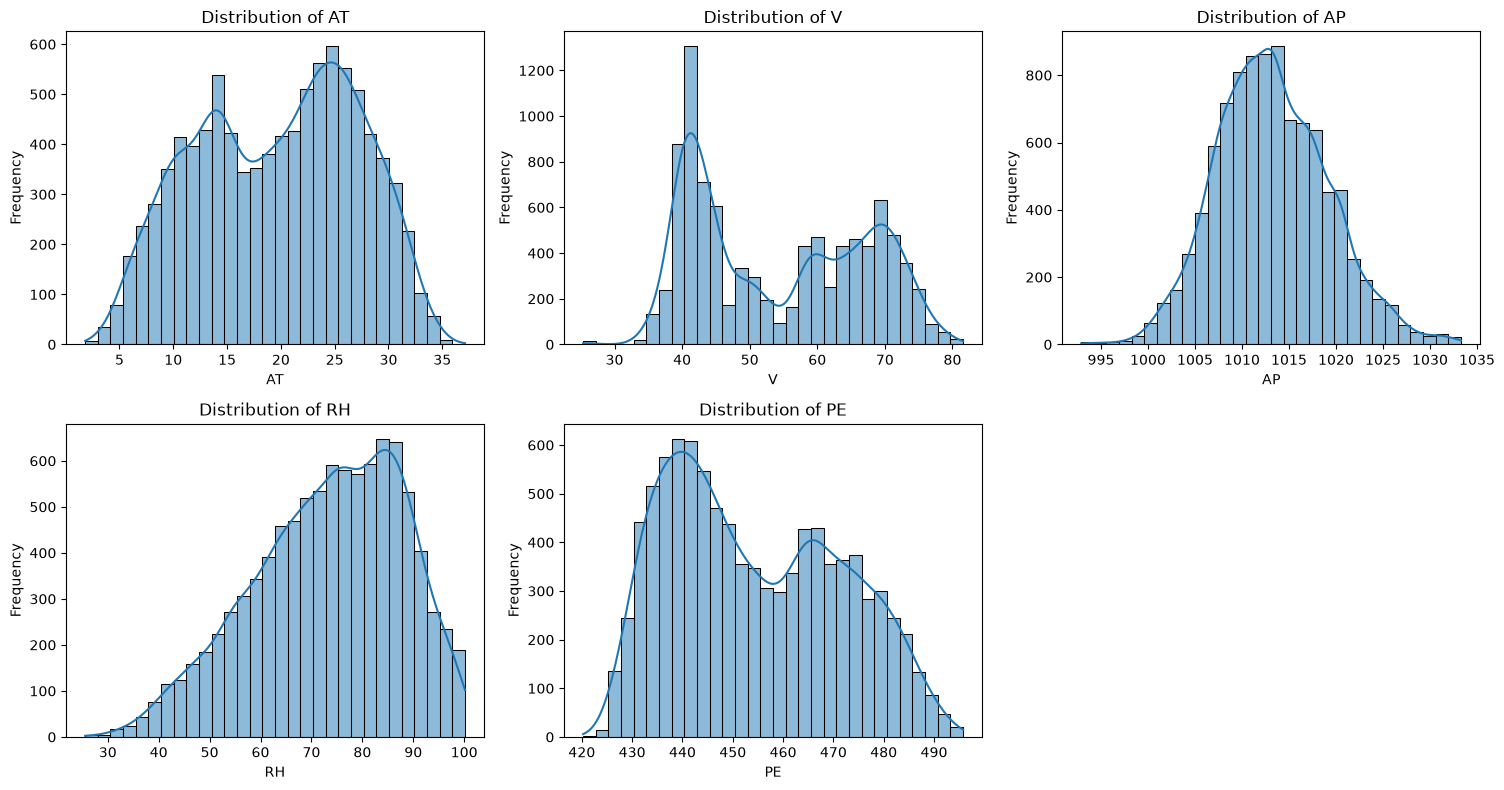

In [19]:
# 直方圖
columns = ["AT", "V", "AP", "RH", "PE"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(columns):
    sns.histplot(
        df_clean[col],
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# 移除多出來的第六張圖
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

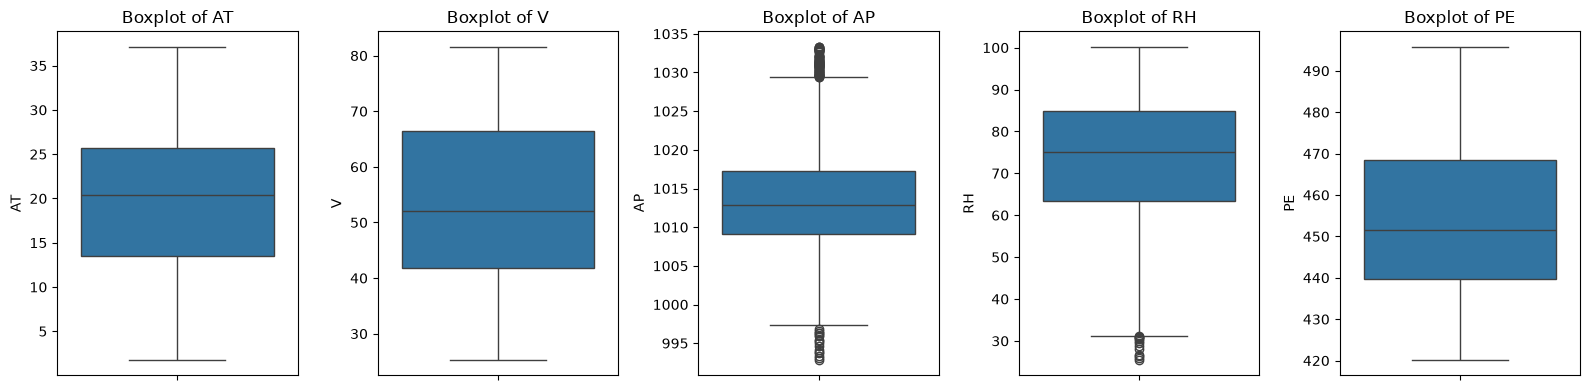

In [ ]:
# 箱型圖
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for i, col in enumerate(columns):
    sns.boxplot(
        y=df_clean[col],
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {col}")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

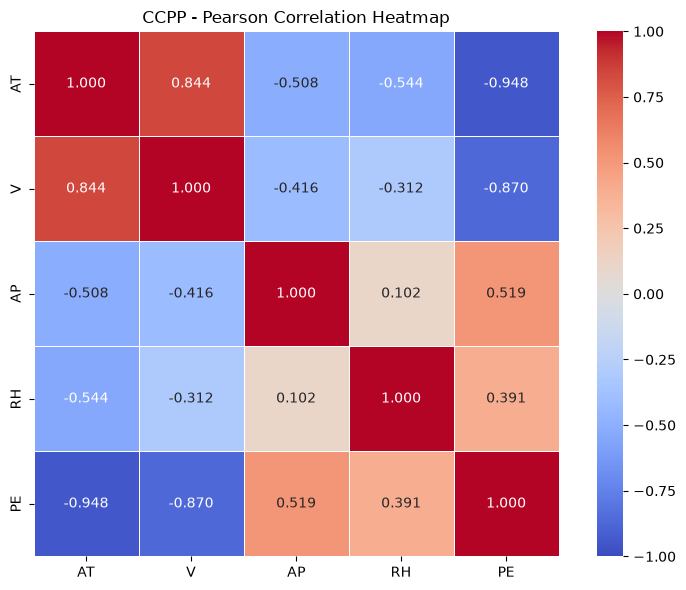

In [ ]:
# 熱力圖
# 計算 Pearson 相關係數
corr_matrix = df_clean[["AT", "V", "AP", "RH", "PE"]].corr(
    method="pearson"
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("CCPP - Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

# Modeling

## Data Spliting
CCPP 的資料版本沒有可直接使用的完整時間欄位，因此目前以固定隨機種子的切分方式進行一般迴歸實驗。這種切分適合評估相似運轉條件下的預測能力，但不應將結果直接解釋為未來時間的發電量預測表現。

In [7]:
from sklearn.model_selection import train_test_split

# 分離自變數 X 與應變數 y
X = df_clean[["AT", "V", "AP", "RH"]]
y = df_clean["PE"]

# 第一次切分：Training 70%、暫存 30%
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# 第二次切分：將暫存資料分成 Validation 與 Testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\n總樣本數：", len(X_train) + len(X_val) + len(X_test))

Training: (6668, 4) (6668,)
Validation: (1429, 4) (1429,)
Testing: (1430, 4) (1430,)

總樣本數： 9527


接下來的 Structure × Sample Size 實驗，會從固定的 Training Data 裡抽取不同筆數，例如 100、300、1,000、3,000 等，Validation 和 Testing 始終固定不變，這樣比較才公平。

## Standardization

對於使用 Linear Summation 的神經元：
\[
z=w_1AT+w_2V+w_3AP+w_4RH+b
\]

如果各變數尺度差異很大，可能讓不同權重的梯度更新尺度不一致，使訓練變得困難。

尤其我們預計使用 Tanh Activation Function，如果神經元的加權輸入 \(z\) 過大或過小，Tanh 容易進入飽和區域，導致梯度變小。

因此，標準化能讓神經網路更容易進行數值最佳化。

In [8]:
from sklearn.preprocessing import StandardScaler

# 建立 X StandardScaler
# Y 先不標準化，因為方便解釋預測結果、不須額外進行反標準化
# 除非模型訓練出現收斂困難
scaler_X = StandardScaler()

# 只使用 Training Data 計算平均數與標準差
X_train_scaled = pd.DataFrame(
    scaler_X.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Validation / Testing 只使用 Training 的標準化參數
X_val_scaled = pd.DataFrame(
    scaler_X.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

X_test_scaled = pd.DataFrame(
    scaler_X.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training 標準化後的前五筆資料：")
display(X_train_scaled.head())

print("\nTraining 各特徵平均值：")
display(X_train_scaled.mean().round(4))

print("\nTraining 各特徵標準差：")
display(X_train_scaled.std(ddof=0).round(4))

Training 標準化後的前五筆資料：


,AT,V,AP,RH
4100,-1.710985,-1.179350,1.036918,-0.283704
471,0.236492,0.695657,0.562662,1.147710
1905,0.734181,1.366771,-0.514118,0.969805
8451,0.704428,0.332039,-0.365596,-0.554309
801,0.793687,1.267171,-0.701457,1.183154



Training 各特徵平均值：


AT   -0.0
V     0.0
AP   -0.0
RH   -0.0
dtype: float64


Training 各特徵標準差：


AT    1.0
V     1.0
AP    1.0
RH    1.0
dtype: float64

In [9]:
from sklearn.preprocessing import StandardScaler

# 建立 Y 的標準化器
scaler_y = StandardScaler()

# 只使用 Training Data 計算平均值與標準差
y_train_scaled = scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

# Validation 只使用 Training 的參數轉換
y_val_scaled = scaler_y.transform(
    y_val.to_numpy().reshape(-1, 1)
)

# Testing 也使用相同參數
y_test_scaled = scaler_y.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("PE Training Mean:", scaler_y.mean_[0])
print("PE Training Std:", scaler_y.scale_[0])

print("\n標準化後的前五筆 PE：")
print(y_train_scaled[:5])

PE Training Mean: 454.2628719256149
PE Training Std: 16.95454068311609

標準化後的前五筆 PE：
[[ 1.98985798]
 [-0.59411058]
 [-1.21990164]
 [-0.59411058]
 [-1.21164426]]


## NN base model

### three-layer 4-4-1_init
hidden: Tanh
Output: Identity
Loss: MSE
Trainable Parameters: 49

為什麼選擇 Tanh Activation Function？
以下可以直接複製到筆記：
- 提供非線性能力：使神經網路能學習輸入變數與 PE 之間可能存在的非線性關係。
- 輸出以 0 為中心：Tanh 的輸出範圍為 (−1, 1)，相較於 Logistic 的 (0, 1)，在某些情況下有利於梯度最佳化。
- 配合輸入標準化：本研究已將四個 X 標準化為平均值約 0、標準差約 1，適合將 Tanh 作為初始的 Hidden Activation。
- 符合連續值預測需求：隱藏層使用 Tanh，輸出層使用 Identity，因此最終預測的 PE 不受 −1～1 限制。
- 固定實驗條件：後續比較 Structure × Sample Size 時，統一使用 Tanh，避免 Activation Function 差異干擾結構比較。
需要補充的是，Tanh 可能出現梯度飽和問題，因此它是合理的起始選擇，不代表已經證明是最佳函數。

In [ ]:

keras.utils.set_random_seed(42)

# Base MLP: 4 → 4 → 1
model = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(4, activation="tanh"),
    layers.Dense(1, activation="linear")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 訓練基本 MLP (4-4-1)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,      # 完整 Training Data 重複訓練 50 回合 改100還是誤差很大
    batch_size=32,  # 每次使用 32 筆資料計算梯度並更新參數
    verbose=1       # 顯示每個 Epoch 的訓練進度
)

Epoch 1/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 157922.8438 - mae: 397.0334 - val_loss: 157958.7812 - val_mae: 397.0635
Epoch 2/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 157103.7188 - mae: 396.0005 - val_loss: 157139.5312 - val_mae: 396.0306
Epoch 3/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 156286.7969 - mae: 394.9677 - val_loss: 156322.6719 - val_mae: 394.9979
Epoch 4/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 155472.0312 - mae: 393.9348 - val_loss: 155507.9219 - val_mae: 393.9652
Epoch 5/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 154659.5938 - mae: 392.9022 - val_loss: 154695.4062 - val_mae: 392.9326
Epoch 6/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 153849.3125 - mae: 391.8697 - val_loss: 153885.1094 - val_mae: 391.9001
Epoch 7/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 153041.2344 - mae: 390.8372 - val_loss: 153076.9531 - val_mae: 390.8678
Epoch 8/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 152235.3

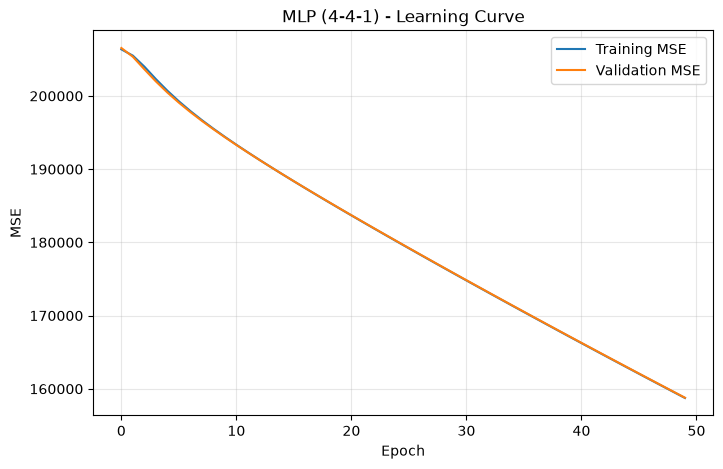

In [26]:
# 畫出training loss 與 validation loss 的變化曲線

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MLP (4-4-1) - Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 小結
MAE 預測誤差過大，因此決定把y做標準化之後再看

### three-layer 4-4-1 std Y

In [ ]:
# 重建一個模型
# 固定隨機種子
keras.utils.set_random_seed(42)

# 重新建立 4-4-1 模型
model_scaled = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(4, activation="tanh"),
    layers.Dense(1, activation="linear")
])

model_scaled.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model_scaled.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

In [27]:
history_scaled = model_scaled.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0602 - mae: 0.1927 - val_loss: 0.0650 - val_mae: 0.1937
Epoch 2/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0602 - mae: 0.1926 - val_loss: 0.0650 - val_mae: 0.1937
Epoch 3/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0602 - mae: 0.1926 - val_loss: 0.0650 - val_mae: 0.1936
Epoch 4/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0602 - mae: 0.1926 - val_loss: 0.0650 - val_mae: 0.1936
Epoch 5/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0602 - mae: 0.1926 - val_loss: 0.0650 - val_mae: 0.1936
Epoch 6/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0602 - mae: 0.1925 - val_loss: 0.0650 - val_mae: 0.1936
Epoch 7/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0601 - mae: 0.1925 - val_loss: 0.0650 - val_mae: 0.1936
Epoch 8/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0601 - mae: 0.1925 - val_loss: 0.0650 - val_mae: 0.1936
Epoch 9/100
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/

因為這次 Y 已經標準化，因此：
- loss：標準化尺度上的 Training MSE。
- val_loss：標準化尺度上的 Validation MSE。
- mae：標準化尺度上的平均絕對誤差，不再直接代表 MW。

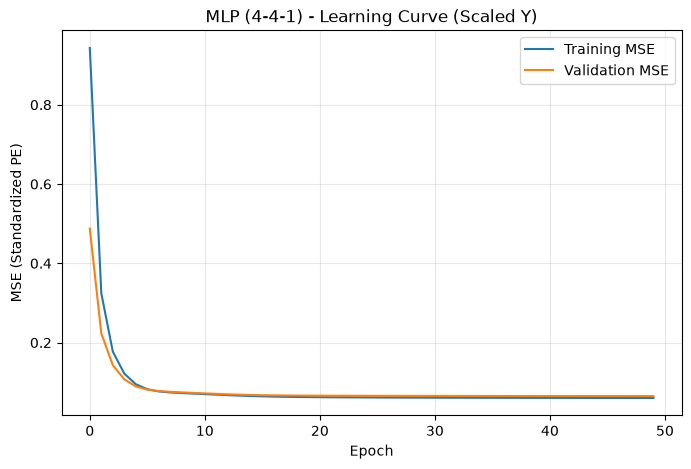

In [26]:
# 標準化Y後的 learning curve
plt.figure(figsize=(8, 5))

plt.plot(
    history_scaled.history["loss"],
    label="Training MSE"
)

plt.plot(
    history_scaled.history["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (Standardized PE)")
plt.title("MLP (4-4-1) - Learning Curve (Scaled Y)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [30]:
# 1. 使用 Validation Data 進行預測
y_val_pred_scaled = model_scaled.predict(
    X_val_scaled,
    verbose=0
)

# 2. 將預測結果反標準化，恢復 MW
y_val_pred = scaler_y.inverse_transform(
    y_val_pred_scaled
).ravel()

# 3. 計算 Validation 指標
val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

val_mae = mean_absolute_error(
    y_val, y_val_pred
)

val_r2 = r2_score(
    y_val, y_val_pred
)

print(f"Validation RMSE: {val_rmse:.4f} MW")
print(f"Validation MAE : {val_mae:.4f} MW")
print(f"Validation R²  : {val_r2:.4f}")

# 4. 顯示前五筆真實值與預測值
results = pd.DataFrame({
    "Actual PE": y_val.to_numpy(),
    "Predicted PE": y_val_pred
})

display(results.head())

Validation RMSE: 4.3166 MW
Validation MAE : 3.2678 MW
Validation R²  : 0.9378


,Actual PE,Predicted PE
0,434.74,436.605072
1,445.03,436.165344
2,475.51,471.563232
3,483.55,480.920959
4,428.12,432.794067


#### 小結

代表模型相較於使用 Validation Data 平均 PE 作為固定預測值，能降低約 93.78% 的平方誤差。
這是相當好的初步結果，但不能說「模型預測正確率是 93.78%」，因為 R² 不是分類準確率。

可以看到模型大致掌握發電量的高低變化，但仍存在個別較大的誤差。

並且可以看出模型的收斂速度會不盡相同，因此後續的模型比較epoch會採用Early Stopping的方式進行。

## NN model w/ 4 structures
Model | Structure | Hidden Layers | Parameters | 比較目的
M1 | 4–4–1 | 1 | 25 | 基本參考模型
M2 | 4–8–1 | 1 | 49 | 觀察增加節點數的影響
M3 | 4–16–1 | 1 | 97 | 觀察進一步增加節點數的影響
M4 | 4–8–4–1 | 2 | 81 | 觀察雙隱藏層架構的表現

### 4-4-1 early

In [ ]:
# M1：4-4-1 w/ early stopping

# 固定隨機種子
keras.utils.set_random_seed(42)

# 建立新的model
model_m1 = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(4, activation="tanh"),
    layers.Dense(1, activation="linear")
])

model_m1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Early Stopping -- 會根據 Validation Loss 決定訓練何時停止
early_stopping_m1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,        # Validation Loss 連續 15 個 Epoch 沒有達到規定的改善幅度
    min_delta=0.0001,   # Early Stopping 就會停止訓練
    restore_best_weights=True
)

model_m1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

In [32]:
history_m1 = model_m1.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping_m1],
    verbose=0
)

print("實際訓練 Epoch 數：", len(history_m1.history["loss"]))
print("最低 Validation MSE：", min(history_m1.history["val_loss"]))

實際訓練 Epoch 數： 61
最低 Validation MSE： 0.06499864906072617


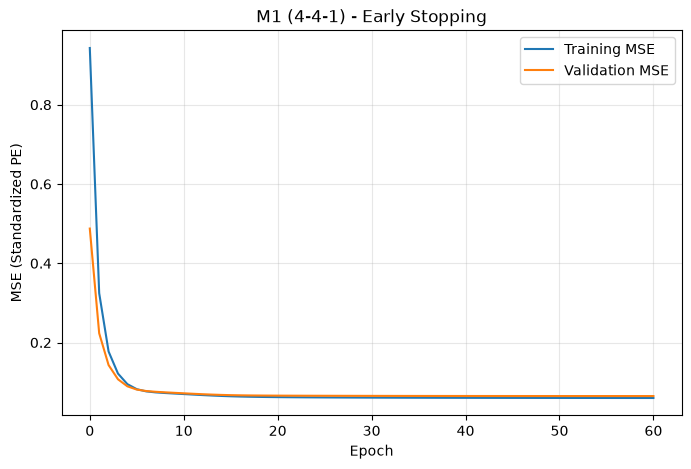

In [33]:
# learning curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_m1.history["loss"],
    label="Training MSE"
)

plt.plot(
    history_m1.history["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (Standardized PE)")
plt.title("M1 (4-4-1) - Early Stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### result

In [34]:
# 找出最低 Validation MSE 對應的 Epoch
best_epoch_m1 = np.argmin(
    history_m1.history["val_loss"]
) + 1

# 使用已恢復最佳權重的 M1 進行 Validation 預測
y_pred_m1_scaled = model_m1.predict(
    X_val_scaled,
    verbose=0
)

# 反標準化，恢復 MW
y_pred_m1 = scaler_y.inverse_transform(
    y_pred_m1_scaled
).ravel()

# 計算 Validation 指標
rmse_m1 = np.sqrt(mean_squared_error(y_val, y_pred_m1))
mae_m1 = mean_absolute_error(y_val, y_pred_m1)
r2_m1 = r2_score(y_val, y_pred_m1)

print(f"Best Epoch: {best_epoch_m1}")
print(f"Validation RMSE: {rmse_m1:.4f} MW")
print(f"Validation MAE : {mae_m1:.4f} MW")
print(f"Validation R²  : {r2_m1:.4f}")

Best Epoch: 61
Validation RMSE: 4.3255 MW
Validation MAE : 3.2857 MW
Validation R²  : 0.9375


### 4-8-1 early

In [35]:
# M2：4-8-1 w/ early stopping

# 固定隨機種子
keras.utils.set_random_seed(42)

# 建立model
model_m2 = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(8, activation="tanh"),
    layers.Dense(1, activation="linear")
])

model_m2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Early Stopping -- 會根據 Validation Loss 決定訓練何時停止
early_stopping_m2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    min_delta=0.0001,
    restore_best_weights=True
)

model_m2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49 (196.00 B)

 Trainable params: 49 (196.00 B)

 Non-trainable params: 0 (0.00 B)

In [36]:
history_m2 = model_m2.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping_m2],
    verbose=0
)

print("實際訓練 Epoch 數：", len(history_m2.history["loss"]))
print("最低 Validation MSE：", min(history_m2.history["val_loss"]))

實際訓練 Epoch 數： 130
最低 Validation MSE： 0.0636615976691246


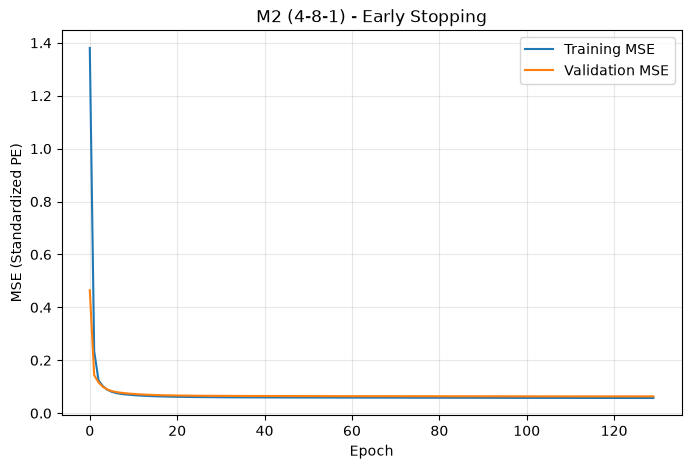

In [37]:
# learning curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_m2.history["loss"],
    label="Training MSE"
)

plt.plot(
    history_m2.history["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (Standardized PE)")
plt.title("M2 (4-8-1) - Early Stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### result

In [38]:
# 最低 Validation MSE 所對應的 Epoch
best_epoch_m2 = np.argmin(
    history_m2.history["val_loss"]
) + 1

# 使用恢復最佳權重後的 M2 預測
y_pred_m2_scaled = model_m2.predict(
    X_val_scaled,
    verbose=0
)

# 反標準化回 MW
y_pred_m2 = scaler_y.inverse_transform(
    y_pred_m2_scaled
).ravel()

rmse_m2 = np.sqrt(mean_squared_error(y_val, y_pred_m2))
mae_m2 = mean_absolute_error(y_val, y_pred_m2)
r2_m2 = r2_score(y_val, y_pred_m2)

print(f"Best Epoch: {best_epoch_m2}")
print(f"Validation RMSE: {rmse_m2:.4f} MW")
print(f"Validation MAE : {mae_m2:.4f} MW")
print(f"Validation R²  : {r2_m2:.4f}")

Best Epoch: 130
Validation RMSE: 4.2795 MW
Validation MAE : 3.2324 MW
Validation R²  : 0.9388


In [39]:
print("實際訓練 Epochs:", len(history_m2.history["loss"]))
print("Early Stopping 停止 Epoch:", early_stopping_m2.stopped_epoch)
print("最低 Validation Loss Epoch:", best_epoch_m2)

print("\n最後 10 個 Epoch 的 Validation MSE:")
print(
    np.round(history_m2.history["val_loss"][-10:], 6)
)

實際訓練 Epochs: 130
Early Stopping 停止 Epoch: 129
最低 Validation Loss Epoch: 130

最後 10 個 Epoch 的 Validation MSE:
[0.063686 0.063683 0.06368  0.063677 0.063674 0.063671 0.063669 0.063666
 0.063664 0.063662]


##### SAVE

In [46]:
from pathlib import Path
import json

# 建立保存模型的資料夾
save_dir = Path("saved_models")
save_dir.mkdir(exist_ok=True)

# 儲存訓練完成的模型
model_m1.save(save_dir / "M1_4-4-1.keras")
model_m2.save(save_dir / "M2_4-8-1.keras")

# 儲存 Learning Curve 紀錄
with open(save_dir / "history_m1.json", "w") as f:
    json.dump(history_m1.history, f)

with open(save_dir / "history_m2.json", "w") as f:
    json.dump(history_m2.history, f)

print("M1、M2 模型與訓練紀錄保存成功")
print("儲存位置：", save_dir.resolve())

M1、M2 模型與訓練紀錄保存成功
儲存位置： C:\Users\USER\115-1_DAM\HW5\saved_models


### 4-16-1 early

In [48]:
# 固定 Random Seed
keras.utils.set_random_seed(42)

# 建立全新的 M3：4 → 16 → 1
model_m3 = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(16, activation="tanh"),
    layers.Dense(1, activation="linear")
])

model_m3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# 建立新的 Early Stopping
early_stopping_m3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    min_delta=0.0001,
    restore_best_weights=True
)

# 從全新權重開始訓練
history_m3 = model_m3.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping_m3],
    verbose=0
)

# 確認訓練結果
print("Actual Epochs:", len(history_m3.history["loss"]))
print("Best Epoch:", np.argmin(history_m3.history["val_loss"]) + 1)
print("Lowest Validation MSE:", min(history_m3.history["val_loss"]))
print("Trainable Parameters:", model_m3.count_params())

Actual Epochs: 180
Best Epoch: 180
Lowest Validation MSE: 0.06215614452958107
Trainable Parameters: 97


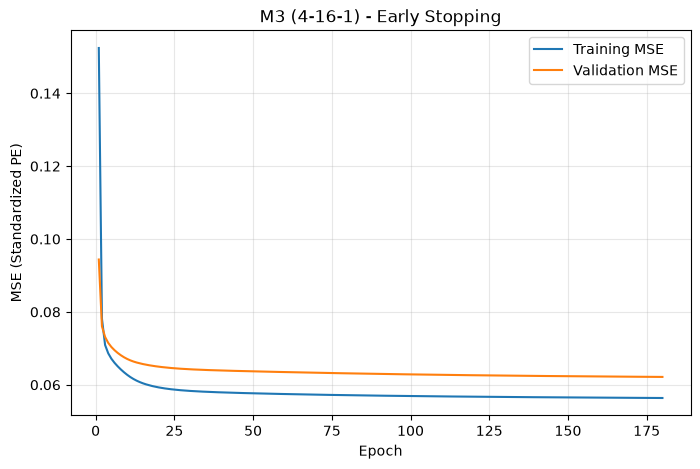

In [49]:
# learning curve

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history_m3.history["loss"]) + 1),
    history_m3.history["loss"],
    label="Training MSE"
)

plt.plot(
    range(1, len(history_m3.history["val_loss"]) + 1),
    history_m3.history["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (Standardized PE)")
plt.title("M3 (4-16-1) - Early Stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### result

In [ ]:
# 最低 Validation MSE 所對應的 Epoch
best_epoch_m3 = np.argmin(
    history_m3.history["val_loss"]
) + 1

# Validation Prediction
y_pred_m3_scaled = model_m3.predict(
    X_val_scaled,
    verbose=0
)

# 反標準化為 MW
y_pred_m3 = scaler_y.inverse_transform(
    y_pred_m3_scaled
).ravel()

# Validation Metrics
rmse_m3 = np.sqrt(mean_squared_error(y_val, y_pred_m3))
mae_m3 = mean_absolute_error(y_val, y_pred_m3)
r2_m3 = r2_score(y_val, y_pred_m3)

print(f"Best Epoch: {best_epoch_m3}")
print(f"Validation RMSE: {rmse_m3:.4f} MW")
print(f"Validation MAE : {mae_m3:.4f} MW")
print(f"Validation R²  : {r2_m3:.4f}")

Best Epoch: 180
Validation RMSE: 4.2301 MW
Validation MAE : 3.1726 MW
Validation R²  : 0.9402


### 4-8-4-1 early

In [52]:
# 固定 Random Seed
keras.utils.set_random_seed(42)

# M4: 4 → 8 → 4 → 1
model_m4 = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(8, activation="tanh"),
    layers.Dense(4, activation="tanh"),
    layers.Dense(1, activation="linear")
])

model_m4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping_m4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    min_delta=0.0001,
    restore_best_weights=True
)

model_m4.summary()

history_m4 = model_m4.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping_m4],
    verbose=0
)

print("Actual Epochs:", len(history_m4.history["loss"]))
print("Best Epoch:", np.argmin(history_m4.history["val_loss"]) + 1)
print("Lowest Validation MSE:", min(history_m4.history["val_loss"]))
print("Trainable Parameters:", model_m4.count_params())

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

Actual Epochs: 173
Best Epoch: 173
Lowest Validation MSE: 0.060822296887636185
Trainable Parameters: 81


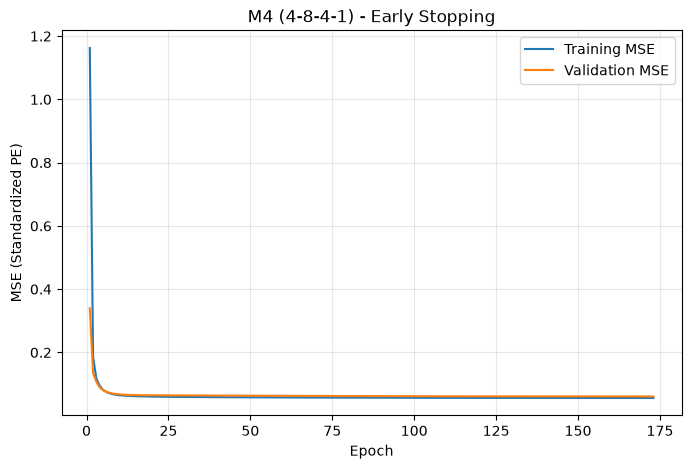

In [53]:
# learning curve

epochs_m4 = range(1, len(history_m4.history["loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_m4,
    history_m4.history["loss"],
    label="Training MSE"
)

plt.plot(
    epochs_m4,
    history_m4.history["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (Standardized PE)")
plt.title("M4 (4-8-4-1) - Early Stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### result

In [54]:
# Validation Prediction
y_pred_m4_scaled = model_m4.predict(
    X_val_scaled,
    verbose=0
)

# 恢復 PE 的 MW 單位
y_pred_m4 = scaler_y.inverse_transform(
    y_pred_m4_scaled
).ravel()

# 計算 Validation Metrics
rmse_m4 = np.sqrt(mean_squared_error(y_val, y_pred_m4))
mae_m4 = mean_absolute_error(y_val, y_pred_m4)
r2_m4 = r2_score(y_val, y_pred_m4)

print(f"Validation RMSE: {rmse_m4:.4f} MW")
print(f"Validation MAE : {mae_m4:.4f} MW")
print(f"Validation R²  : {r2_m4:.4f}")

Validation RMSE: 4.1836 MW
Validation MAE : 3.1165 MW
Validation R²  : 0.9415


##### SAVE

In [ ]:
save_dir = Path("saved_models")
save_dir.mkdir(exist_ok=True)

# 保存 M3、M4
model_m3.save(save_dir / "M3_4-16-1.keras")
model_m4.save(save_dir / "M4_4-8-4-1.keras")

# 保存訓練歷史
for name, history in [
    ("m3", history_m3),
    ("m4", history_m4)
]:
    with open(save_dir / f"history_{name}.json", "w") as f:
        json.dump(history.history, f)

print("M3、M4 保存完成")

M3、M4 保存完成


In [12]:
# 確認有儲存完成
# 儲存模型避免下次開啟notebook時需要重新訓練
from tensorflow import keras

model_files = {
    "M1": ("M1_4-4-1.keras", 25),
    "M2": ("M2_4-8-1.keras", 49),
    "M3": ("M3_4-16-1.keras", 97),
    "M4": ("M4_4-8-4-1.keras", 81)
}

for name, (filename, expected_params) in model_files.items():
    path = save_dir / filename

    if not path.exists():
        print(f"{name}: Missing")
        continue

    loaded = keras.models.load_model(path)

    print(
        f"{name}: OK | "
        f"Parameters = {loaded.count_params()} | "
        f"Correct = {loaded.count_params() == expected_params}"
    )

NameError: name 'save_dir' is not defined

###### 下次開啟執行

In [15]:
# 下次開啟執行

save_dir = Path("saved_models")

models = {}
histories = {}

model_files = {
    "M1": "M1_4-4-1.keras",
    "M2": "M2_4-8-1.keras",
    "M3": "M3_4-16-1.keras",
    "M4": "M4_4-8-4-1.keras"
}

for name, filename in model_files.items():
    models[name] = keras.models.load_model(save_dir / filename)

    with open(save_dir / f"history_{name.lower()}.json") as f:
        histories[name] = json.load(f)

print("四個模型與訓練紀錄載入完成")

四個模型與訓練紀錄載入完成


### Model Performance Comparison

In [16]:
# 整理已訓練的模型
models = {
    "M1": model_m1,
    "M2": model_m2,
    "M3": model_m3,
    "M4": model_m4
}

# 整理各模型的訓練歷史
histories = {
    "M1": history_m1.history,
    "M2": history_m2.history,
    "M3": history_m3.history,
    "M4": history_m4.history
}

print("Models:", list(models.keys()))
print("Histories:", list(histories.keys()))

NameError: name 'model_m1' is not defined

In [17]:
# 四種模型的基本資訊
model_info = {
    "M1": {"Structure": "4-4-1", "Parameters": 25},
    "M2": {"Structure": "4-8-1", "Parameters": 49},
    "M3": {"Structure": "4-16-1", "Parameters": 97},
    "M4": {"Structure": "4-8-4-1", "Parameters": 81}
}

comparison_results = []

for name, info in model_info.items():

    # 使用載入後的模型預測 Validation Data
    y_pred_scaled = models[name].predict(
        X_val_scaled,
        verbose=0
    )

    # 反標準化，恢復 MW
    y_pred = scaler_y.inverse_transform(
        y_pred_scaled
    ).ravel()

    # 計算評估指標
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)

    # 取得訓練歷史
    history = histories[name]

    actual_epochs = len(history["loss"])
    best_epoch = np.argmin(history["val_loss"]) + 1

    comparison_results.append({
        "Model": name,
        "Structure": info["Structure"],
        "Parameters": info["Parameters"],
        "Actual Epochs": actual_epochs,
        "Best Epoch": best_epoch,
        "Val RMSE (MW)": rmse,
        "Val MAE (MW)": mae,
        "Val R²": r2
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,Structure,Parameters,Actual Epochs,Best Epoch,Val RMSE (MW),Val MAE (MW),Val R²
0,M1,4-4-1,25,61,61,4.3255,3.2857,0.9375
1,M2,4-8-1,49,130,130,4.2795,3.2324,0.9388
2,M3,4-16-1,97,180,180,4.2301,3.1726,0.9402
3,M4,4-8-4-1,81,173,173,4.1836,3.1165,0.9415


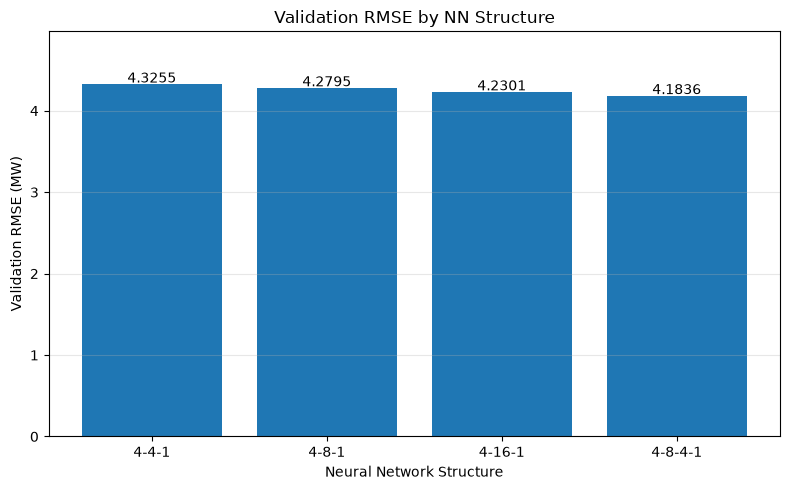

In [18]:
# 各 Structure 的 Validation RMSE
plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison_df["Structure"],
    comparison_df["Val RMSE (MW)"]
)

for bar, value in zip(
    bars,
    comparison_df["Val RMSE (MW)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.xlabel("Neural Network Structure")
plt.ylabel("Validation RMSE (MW)")
plt.title("Validation RMSE by NN Structure")

plt.ylim(0, comparison_df["Val RMSE (MW)"].max() * 1.15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

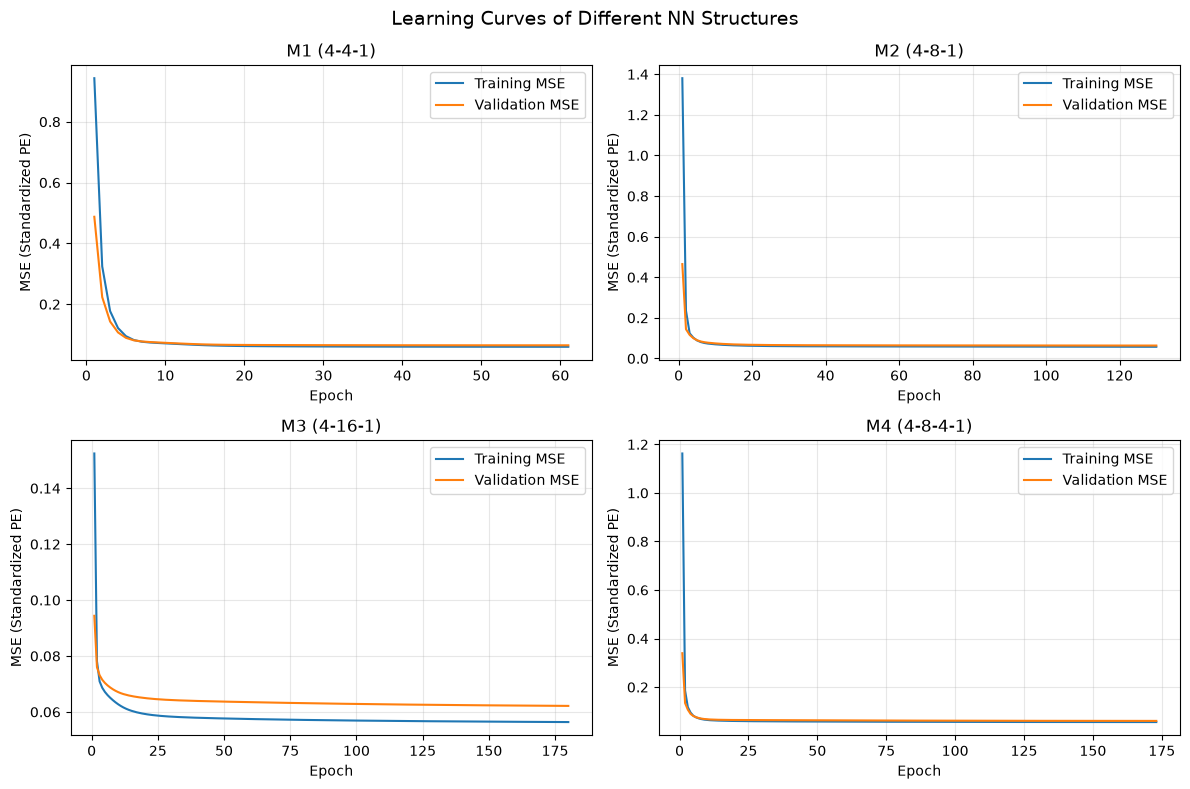

In [19]:
# 四個模型的learning curve

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, name in zip(axes.flatten(), model_info.keys()):

    history = histories[name]
    epochs = range(1, len(history["loss"]) + 1)

    ax.plot(
        epochs,
        history["loss"],
        label="Training MSE"
    )

    ax.plot(
        epochs,
        history["val_loss"],
        label="Validation MSE"
    )

    ax.set_title(
        f"{name} ({model_info[name]['Structure']})"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (Standardized PE)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Learning Curves of Different NN Structures",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
# restart check
print("=== Data Verification ===")

print("Original Data:", df.shape)
print("Clean Data:", df_clean.shape)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("\nPE Training Mean:", scaler_y.mean_[0])
print("PE Training Std:", scaler_y.scale_[0])

assert df.shape == (9568, 5)
assert df_clean.shape == (9527, 5)

assert X_train_scaled.shape == (6668, 4)
assert X_val_scaled.shape == (1429, 4)
assert X_test_scaled.shape == (1430, 4)

assert np.isclose(scaler_y.mean_[0], 454.2628719256149)
assert np.isclose(scaler_y.scale_[0], 16.95454068311609)

print("\nData Verification Passed!")

=== Data Verification ===
Original Data: (9568, 5)
Clean Data: (9527, 5)
Training: (6668, 4)
Validation: (1429, 4)
Testing: (1430, 4)

PE Training Mean: 454.2628719256149
PE Training Std: 16.95454068311609

Data Verification Passed!


# Comparing to regression

## Multiple Linear Regression Baseline

In [21]:
from sklearn.linear_model import LinearRegression

# 建立 Multiple Linear Regression 模型
lr_model = LinearRegression()

# 使用相同的 Training Data
# X 與 Y 都沿用先前的標準化資料
lr_model.fit(
    X_train_scaled,
    y_train_scaled.ravel()
)

print("Linear Regression 訓練完成")

print("Intercept:", lr_model.intercept_)
print("Coefficients:", lr_model.coef_)

Linear Regression 訓練完成
Intercept: -9.092253509324616e-16
Coefficients: [-0.86038379 -0.1764072   0.02398921 -0.13341291]


In [22]:
# 1. 使用 Validation Data 預測
y_pred_lr_scaled = lr_model.predict(X_val_scaled)

# 2. 將預測值反標準化，恢復 MW
y_pred_lr = scaler_y.inverse_transform(
    y_pred_lr_scaled.reshape(-1, 1)
).ravel()

# 3. 計算 Validation Metrics
rmse_lr = np.sqrt(mean_squared_error(y_val, y_pred_lr))
mae_lr = mean_absolute_error(y_val, y_pred_lr)
r2_lr = r2_score(y_val, y_pred_lr)

print(f"Validation RMSE: {rmse_lr:.4f} MW")
print(f"Validation MAE : {mae_lr:.4f} MW")
print(f"Validation R²  : {r2_lr:.4f}")

Validation RMSE: 4.6303 MW
Validation MAE : 3.5872 MW
Validation R²  : 0.9284


In [23]:
# comparsion table

# 保留 Step 4 原本的比較表
comparison_all = comparison_df.copy()

# 加入 Linear Regression 的 Validation 結果
comparison_all.loc[len(comparison_all)] = {
    "Model": "Linear Regression",
    "Structure": "Linear",
    "Parameters": 5,
    "Actual Epochs": np.nan,
    "Best Epoch": np.nan,
    "Val RMSE (MW)": rmse_lr,
    "Val MAE (MW)": mae_lr,
    "Val R²": r2_lr
}

display(comparison_all.round(4))

,Model,Structure,Parameters,Actual Epochs,Best Epoch,Val RMSE (MW),Val MAE (MW),Val R²
0,M1,4-4-1,25,61.0,61.0,4.3255,3.2857,0.9375
1,M2,4-8-1,49,130.0,130.0,4.2795,3.2324,0.9388
2,M3,4-16-1,97,180.0,180.0,4.2301,3.1726,0.9402
3,M4,4-8-4-1,81,173.0,173.0,4.1836,3.1165,0.9415
4,Linear Regression,Linear,5,NaN,NaN,4.6303,3.5872,0.9284


In [24]:
# testing data evaluation

# 1. M4：使用 Testing Data 預測
y_test_pred_m4_scaled = models["M4"].predict(
    X_test_scaled,
    verbose=0
)

y_test_pred_m4 = scaler_y.inverse_transform(
    y_test_pred_m4_scaled
).ravel()

# 2. Linear Regression：使用 Testing Data 預測
y_test_pred_lr_scaled = lr_model.predict(
    X_test_scaled
)

y_test_pred_lr = scaler_y.inverse_transform(
    y_test_pred_lr_scaled.reshape(-1, 1)
).ravel()

# 3. 統一計算測試指標
def evaluate_regression(y_true, y_pred):
    return {
        "Test RMSE (MW)": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "Test MAE (MW)": mean_absolute_error(
            y_true, y_pred
        ),
        "Test R²": r2_score(
            y_true, y_pred
        )
    }

testing_results = pd.DataFrame([
    {
        "Model": "M4 (4-8-4-1)",
        **evaluate_regression(y_test, y_test_pred_m4)
    },
    {
        "Model": "Multiple Linear Regression",
        **evaluate_regression(y_test, y_test_pred_lr)
    }
])

display(testing_results.round(4))

,Model,Test RMSE (MW),Test MAE (MW),Test R²
0,M4 (4-8-4-1),4.2935,3.2432,0.9373
1,Multiple Linear Regression,4.7436,3.7565,0.9235
